# Simplified EDA: Predicting Machine Maintenance

**Goal of the project:** build an alert system that tells the maintenance team when a machine needs maintenance, so that machines do not break down unexpectedly.

**Target column:** `maintenance_required` (0 = no, 1 = yes)

**What this notebook does:** this is the EDA (Task 1). We explore and clean the data to understand it. No models are trained here; that is done in the pipeline (Task 2).

Each step follows the same order:
1. **Question:** what we want to find out, and why.
2. **Code:** the check we run.
3. **Findings:** what the output shows.

### Contents
1. Loading the data
2. Target column
3. Sensor columns
4. Derived columns
5. Cleaning the data
6. Derived columns vs target
7. Sensors vs target
8. Machine and time
9. Decisions
10. Summary

## 1. Loading the data
**Question:** did the data load correctly? We check the size, column types, missing values, duplicates and time range before doing anything else.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

TARGET = "maintenance_required"
SENSORS = ["temperature", "vibration", "humidity", "pressure", "energy_consumption"]

df = pd.read_csv("data/proj_machine_readings.csv", parse_dates=["timestamp"])
print(df.shape)
df.head()

(100000, 13)


,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,NaN,-28.65,79.96,3.73,2.16,1,0,106,Normal,0.0,0
1,2025-01-01 00:01:00,29,68.19,57.28,35.94,3.64,0.69,1,0,320,Normal,0.0,0
2,2025-01-01 00:02:00,15,98.94,50.20,72.06,1.00,2.49,1,1,19,Normal,1.0,1
3,2025-01-01 00:03:00,43,90.91,37.65,30.34,3.15,4.96,1,1,10,Normal,1.0,1
4,2025-01-01 00:04:00,8,72.32,40.69,56.71,2.68,0.63,2,0,65,Vibration Issue,0.0,1


**Why this table:** `info()` shows each column's type and how many values are filled in.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   timestamp                 100000 non-null  datetime64[us]
 1   machine_id                100000 non-null  int64         
 2   temperature               86000 non-null   float64       
 3   vibration                 100000 non-null  float64       
 4   humidity                  100000 non-null  float64       
 5   pressure                  100000 non-null  float64       
 6   energy_consumption        100000 non-null  float64       
 7   machine_status            100000 non-null  int64         
 8   anomaly_flag              100000 non-null  int64         
 9   predicted_remaining_life  100000 non-null  int64         
 10  failure_type              100000 non-null  str           
 11  downtime_risk             100000 non-null  float64       
 12  maintenance_re

In [3]:
print("Duplicate rows:", df.duplicated().sum())
print("Time range:", df["timestamp"].min(), "to", df["timestamp"].max())
print("Every row exactly 1 minute after the previous one:", (df["timestamp"].diff().dropna() == pd.Timedelta("1min")).all())
print("Number of machines:", df["machine_id"].nunique())
print("Readings per machine:", df["machine_id"].value_counts().min(), "to", df["machine_id"].value_counts().max())

Duplicate rows: 0
Time range: 2025-01-01 00:00:00 to 2025-03-11 10:39:00
Every row exactly 1 minute after the previous one: True
Number of machines: 50
Readings per machine: 1906 to 2092


**Findings**
- 100,000 rows and 13 columns. All types are correct, and `timestamp` was read as a date.
- Only `temperature` has missing values (86,000 of 100,000 filled, so 14,000 are missing).
- There are no duplicate rows.
- There is one reading every minute, from 1 Jan to 11 Mar 2025, spread across 50 machines (about 2,000 readings each).
- `machine_id`, `machine_status`, `anomaly_flag` and `maintenance_required` are stored as numbers, but they are really **labels**, not amounts.

## 2. Target column
**Question:** how many readings need maintenance? If one class is much bigger than the other, accuracy alone can be misleading.

maintenance_required
0    80303
1    19697
Name: count, dtype: int64
maintenance_required
0    80.3
1    19.7
Name: count, dtype: float64


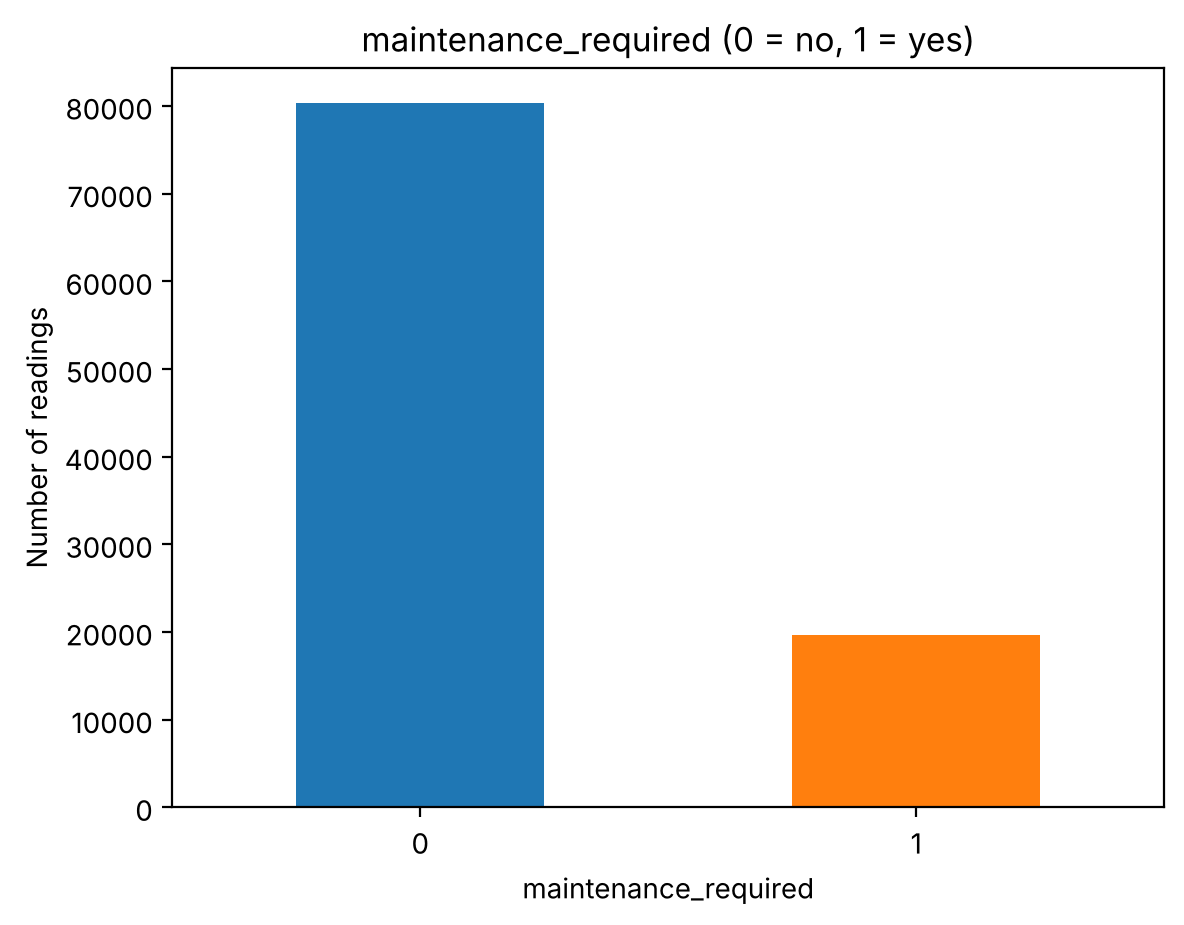

In [4]:
counts = df[TARGET].value_counts()
print(counts)
print((counts / len(df) * 100).round(1))

counts.plot(kind="bar", color=["tab:blue", "tab:orange"], title="maintenance_required (0 = no, 1 = yes)")
plt.ylabel("Number of readings")
plt.xticks(rotation=0)
plt.show()

**Findings**
- 19.7 % of readings need maintenance and 80.3 % do not, so the classes are **imbalanced**.
- A model that always says "no maintenance" would already be 80 % accurate, while missing every machine that needs help. **Accuracy alone is not a good measure.**
- A missed breakdown is worse than a false alarm, so Task 2 should focus on **recall**: how many real maintenance cases we catch.

## 3. Sensor columns
**Question:** do the sensor values look reasonable? We look for impossible values, outliers and the shape of each sensor.

**Why this table:** `describe()` gives the minimum, maximum, average and spread of each sensor. We add a **skew** row to check whether each sensor is symmetric:
- skew close to **0** = symmetric;
- skew **below 0** = a long tail on the left;
- skew **above 0** = a long tail on the right.

The shape matters for Task 2, because some models (such as Gaussian Naive Bayes) assume each feature is bell-shaped.

In [5]:
summary = df[SENSORS].describe()
summary.loc["skew"] = df[SENSORS].skew()
summary.round(2)

,temperature,vibration,humidity,pressure,energy_consumption
count,86000.00,100000.00,100000.00,100000.00,100000.00
mean,75.03,43.32,55.00,3.00,2.75
std,10.04,29.13,14.44,1.15,1.30
min,35.55,-106.98,30.00,1.00,0.50
25%,68.28,37.22,42.52,2.00,1.63
50%,75.09,48.64,54.98,3.01,2.74
75%,81.78,59.25,67.50,4.00,3.87
max,121.94,113.80,80.00,5.00,5.00
skew,-0.01,-2.19,0.00,-0.00,0.01


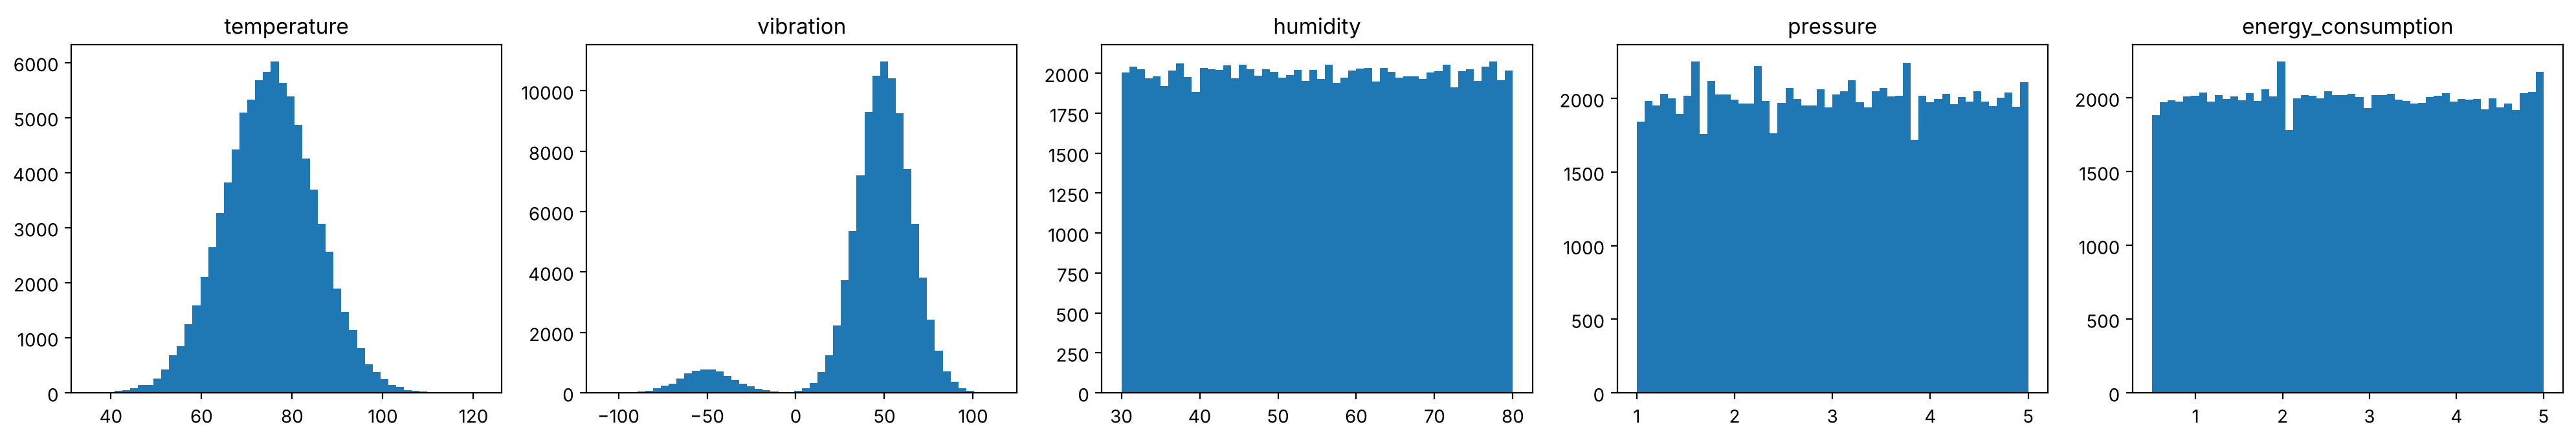

Negative vibration values: 6703 (6.7%)


In [6]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, col in zip(axes, SENSORS):
    ax.hist(df[col].dropna(), bins=50)
    ax.set_title(col)
plt.tight_layout()
plt.show()

print("Negative vibration values:", (df["vibration"] < 0).sum(), f"({(df['vibration'] < 0).mean():.1%})")

**Findings**
- **temperature:** bell-shaped around 75 °C, ranging from 35.6 to 121.9 °C, with skew about 0 (symmetric).
- **vibration:** mostly around 50 mm/s, but the minimum is **-106.98**, and 6,703 values (6.7 %) are negative. These negative values give it a skew of **-2.19** (a long left tail). A vibration level cannot be below zero, so we check this in Section 5.
- **humidity** (30 to 80 %), **pressure** (1 to 5 bar) and **energy_consumption** (0.5 to 5 kWh) have skew about 0, but their histograms are **flat, not bell-shaped**. A skew of 0 only means *symmetric*, and a flat shape is symmetric too. So these three are **not normally distributed**. Real sensors usually cluster around a normal value, so the data is probably **simulated**.
- *For Task 2:* these three flat sensors break the bell-shape assumption of models like Gaussian Naive Bayes.

## 4. Derived columns
**Question:** what values do the derived columns (the columns calculated from other data) contain? We need to understand them before using them.

**Why these tables:** the value counts show how often each value appears.

In [7]:
for col in ["machine_status", "anomaly_flag", "failure_type", "downtime_risk"]:
    print(df[col].value_counts(), "\n")

machine_status
1    80091
2    10057
0     9852
Name: count, dtype: int64 

anomaly_flag
0    91084
1     8916
Name: count, dtype: int64 

failure_type
Normal              91899
Vibration Issue      3129
Overheating          1989
Pressure Drop        1969
Electrical Fault     1014
Name: count, dtype: int64 

downtime_risk
0.00    91084
1.00     8904
0.98        3
0.99        3
0.97        2
0.92        1
0.94        1
0.88        1
0.93        1
Name: count, dtype: int64 



**Question:** `failure_type` should only be filled in when a machine fails (`machine_status` = 2). Is that true?

**Why this table:** it counts every combination of status and failure type.

In [8]:
pd.crosstab(df["machine_status"], df["failure_type"])

failure_type,Electrical Fault,Normal,Overheating,Pressure Drop,Vibration Issue
machine_status,,,,,
0,0,9852,0,0,0
1,0,80091,0,0,0
2,1014,1956,1989,1969,3129


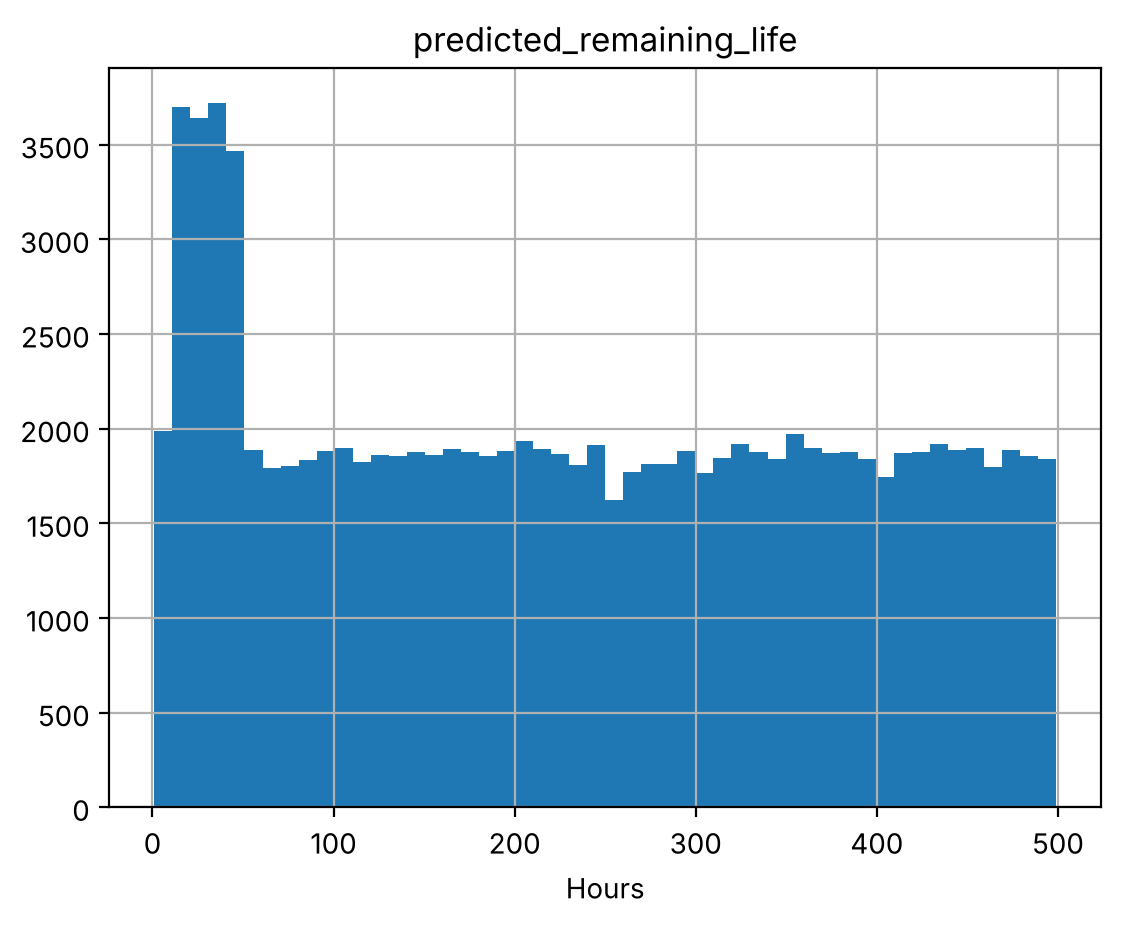

In [9]:
df["predicted_remaining_life"].hist(bins=50)
plt.title("predicted_remaining_life")
plt.xlabel("Hours")
plt.show()

**Findings**
- `machine_status`: 80 % running (1), 10 % idle (0), 10 % failed (2).
- `anomaly_flag`: 8.9 % of readings are flagged as unusual.
- `failure_type` only has real failure types when status = 2. However, **1,956 failed readings are labelled "Normal"**, which does not make sense. We cannot know the correct label, so we leave them as they are.
- `downtime_risk` is almost always exactly 0 or 1 (only 12 values in between).
- `predicted_remaining_life` goes from 1 to 499 hours, with extra readings below 50 hours.

## 5. Cleaning the data
We work on a copy (`df_clean`) so the original data stays unchanged.

In [10]:
df_clean = df.copy()

### 5.1 Negative vibration
**Hypothesis:** the negative values are real readings that were saved with a wrong minus sign.

If this is true:
1. The negative values, with the minus sign removed, should look like the positive values.
2. `anomaly_flag` marks high vibration, so a reading of -85 should be flagged just like +85.

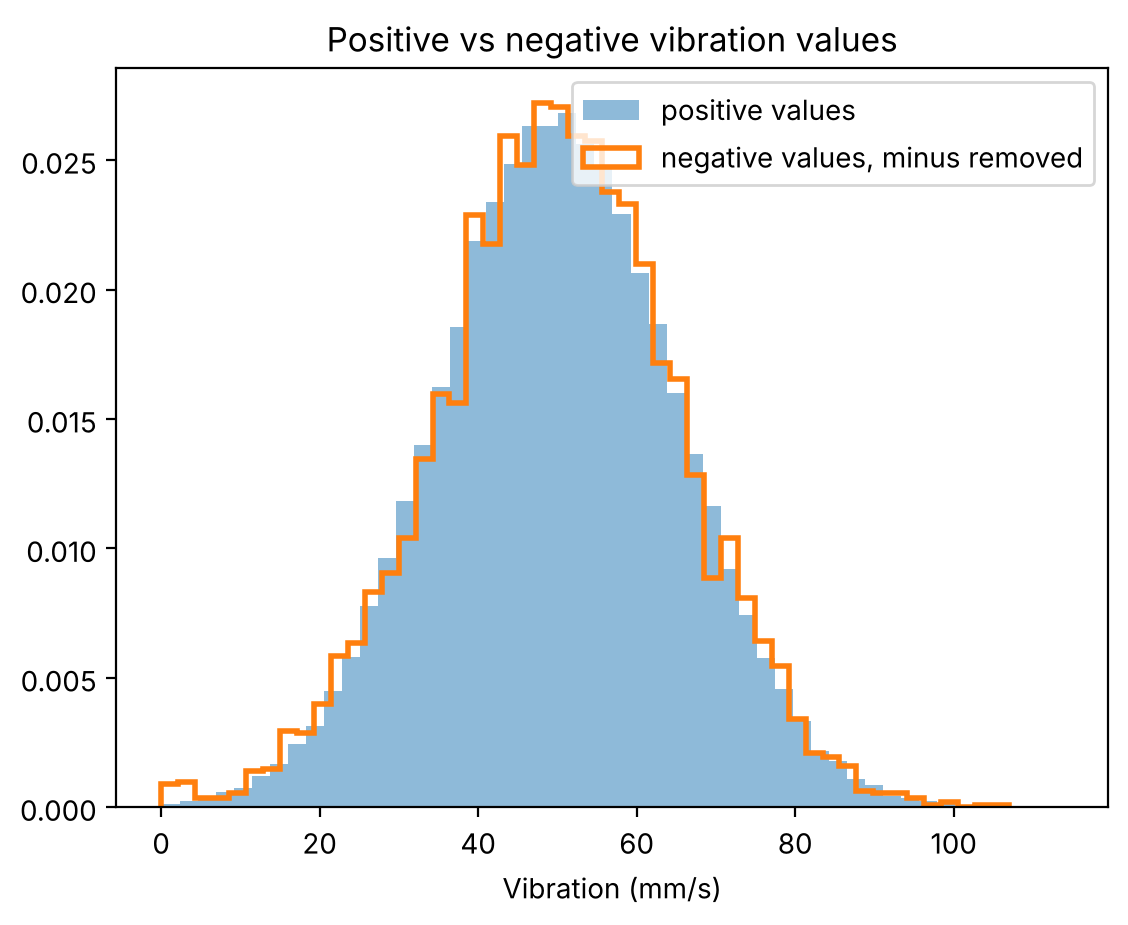

Average of positive values: 50.02
Average of negative values (minus removed): 49.91


In [11]:
positive = df.loc[df["vibration"] >= 0, "vibration"]
negative_flipped = -df.loc[df["vibration"] < 0, "vibration"]

plt.hist(positive, bins=50, density=True, alpha=0.5, label="positive values")
plt.hist(negative_flipped, bins=50, density=True, histtype="step", linewidth=2, label="negative values, minus removed")
plt.title("Positive vs negative vibration values")
plt.xlabel("Vibration (mm/s)")
plt.legend()
plt.show()

print("Average of positive values:", round(positive.mean(), 2))
print("Average of negative values (minus removed):", round(negative_flipped.mean(), 2))

**Why this table:** it shows how often each vibration group is flagged as an anomaly. We only use rows below 90 °C, so that the flag can only come from vibration and not from temperature.

In [12]:
normal_temp = df["temperature"] < 90
groups = {
    "below -80": (df["vibration"] < -80) & normal_temp,
    "-80 to 0": (df["vibration"] >= -80) & (df["vibration"] < 0) & normal_temp,
    "0 to 80": (df["vibration"] >= 0) & (df["vibration"] < 80) & normal_temp,
    "above 80": (df["vibration"] > 80) & normal_temp,
}
pd.DataFrame({
    "rows": {name: rows.sum() for name, rows in groups.items()},
    "% flagged as anomaly": {name: df.loc[rows, "anomaly_flag"].mean() * 100 for name, rows in groups.items()},
})

,rows,% flagged as anomaly
below -80,110,100.0
-80 to 0,4891,0.0
0 to 80,73413,0.0
above 80,1741,100.0


**Findings**
1. The negative values (minus removed) have the same shape and almost the same average (49.91 vs 50.02) as the positive values.
2. Readings below -80 are flagged 100 % of the time, the same as readings above +80. So the flag treats -85 like +85.

Both checks support the hypothesis.

**Decision:** take the **absolute value** of vibration. Removing these rows would throw away 6.7 % of the data, and keeping them would make -85 look like very low vibration.

In [13]:
df_clean["vibration"] = df_clean["vibration"].abs()
print("Negative values left:", (df_clean["vibration"] < 0).sum())
print("Vibration skew before:", round(df["vibration"].skew(), 2), "| after:", round(df_clean["vibration"].skew(), 2))

Negative values left: 0
Vibration skew before: -2.19 | after: 0.01


**Findings:** no negative values are left, and vibration's skew went from -2.19 to about 0, so it is now **symmetric and bell-shaped**, like temperature.

### 5.2 Missing temperature
**Question:** are the rows with missing temperature different from the other rows? If they are, the gaps might carry meaning, and filling them in could hide it.

**Why this table:** it compares the maintenance rate and anomaly rate for rows with and without temperature.

In [14]:
missing = df_clean["temperature"].isna()
comparison = df_clean.groupby(missing)[[TARGET, "anomaly_flag"]].mean() * 100
comparison.index = ["temperature known", "temperature missing"]
comparison.round(1)

,maintenance_required,anomaly_flag
temperature known,19.7,8.9
temperature missing,19.4,8.8


In [15]:
missing_per_machine = missing.groupby(df_clean["machine_id"]).mean() * 100
print("Missing % per machine:", round(missing_per_machine.min(), 1), "to", round(missing_per_machine.max(), 1))

Missing % per machine: 12.6 to 15.7


**Findings:** rows with and without temperature have almost the same maintenance rate (19.4 % vs 19.7 %) and anomaly rate (8.8 % vs 8.9 %). Every machine has a similar share missing (12.6 % to 15.7 %). The values seem to be missing **at random**.

**Question:** which value should we fill the gaps with? Could the other sensors help us guess the missing temperature?

**Why this table:** it compares the mean and median, and shows the correlation of temperature with the other sensors.

In [16]:
print("Mean temperature:  ", round(df_clean["temperature"].mean(), 2))
print("Median temperature:", round(df_clean["temperature"].median(), 2))
print()
print("Correlation of temperature with the other sensors:")
print(df_clean[SENSORS].corr()["temperature"].round(3))

Mean temperature:   75.03
Median temperature: 75.09

Correlation of temperature with the other sensors:
temperature           1.000
vibration            -0.003
humidity              0.003
pressure             -0.001
energy_consumption    0.004
Name: temperature, dtype: float64


**Findings:**
- The mean and median are almost the same (75.0 °C). We choose the **median**, because extreme values affect it less.
- Temperature has **no correlation** with any other sensor (all close to 0), so the other sensors cannot help guess it.

**Question:** if we fill the gaps with 75 °C, would those rows look like normal 75 °C readings? We compare their maintenance rate with real readings between 70 and 80 °C.

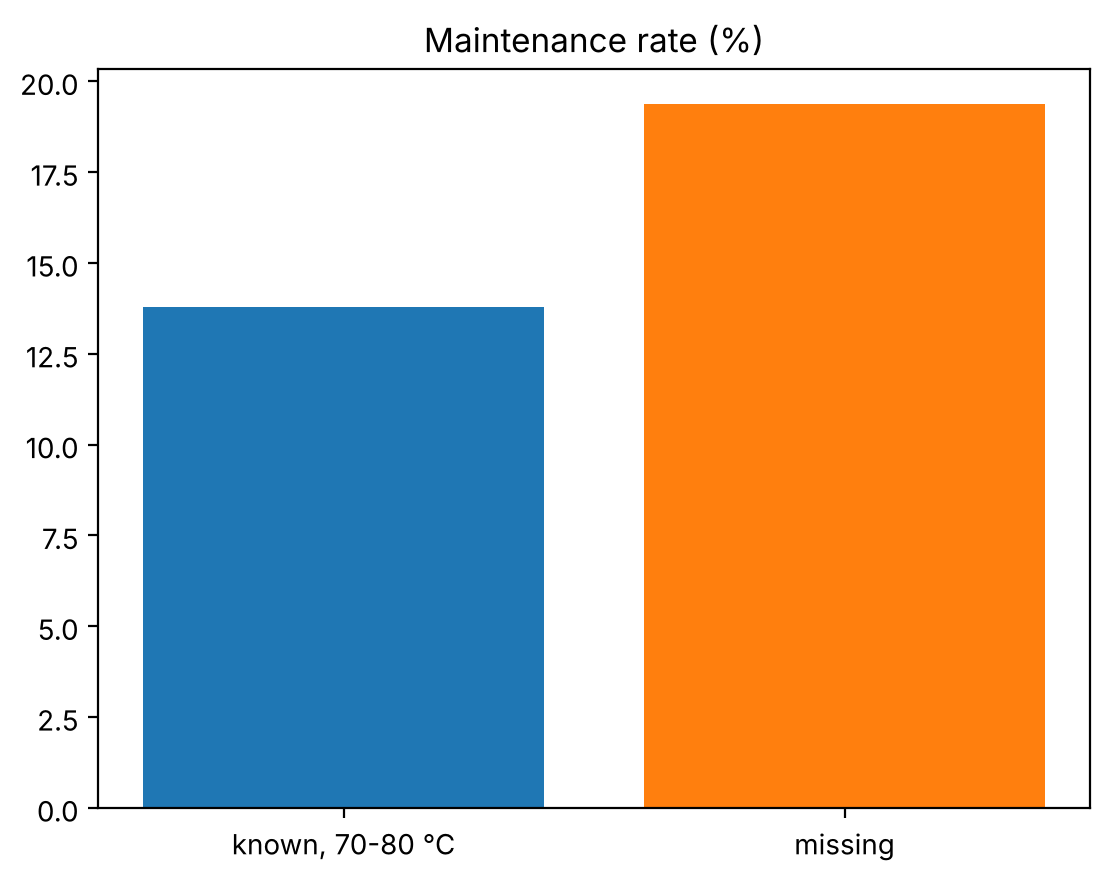

known, 70-80 °C: 13.8 %
missing: 19.4 %


In [17]:
rates = {
    "known, 70-80 °C": df_clean.loc[df_clean["temperature"].between(70, 80), TARGET].mean() * 100,
    "missing": df_clean.loc[missing, TARGET].mean() * 100,
}
plt.bar(rates.keys(), rates.values(), color=["tab:blue", "tab:orange"])
plt.title("Maintenance rate (%)")
plt.show()
for name, value in rates.items():
    print(f"{name}: {value:.1f} %")

**Findings:** rows with missing temperature need maintenance more often (19.4 %) than real readings near 75 °C (13.8 %). This is probably because some of the missing values were actually high temperatures. If we only fill in 75 °C, these rows would look safer than they are.

**Decision:** fill missing temperatures with the **median**, and add a column **`temperature_missing`** (1 = was missing), so that a model can learn that these rows are riskier.

*For Task 2:* the median must be calculated from the **training data only**. Here we use the whole dataset only for exploring.

In [18]:
df_clean["temperature_missing"] = missing.astype(int)
df_clean["temperature_filled"] = df_clean["temperature"].fillna(df_clean["temperature"].median())
df_clean[["temperature", "temperature_filled", "temperature_missing"]].describe().round(2)

,temperature,temperature_filled,temperature_missing
count,86000.00,100000.00,100000.00
mean,75.03,75.04,0.14
std,10.04,9.31,0.35
min,35.55,35.55,0.00
25%,68.28,69.50,0.00
50%,75.09,75.09,0.00
75%,81.78,80.58,0.00
max,121.94,121.94,1.00


### 5.3 Outliers
**Question:** are there outliers in the sensors, and are they mistakes (to remove) or real readings (to keep)?

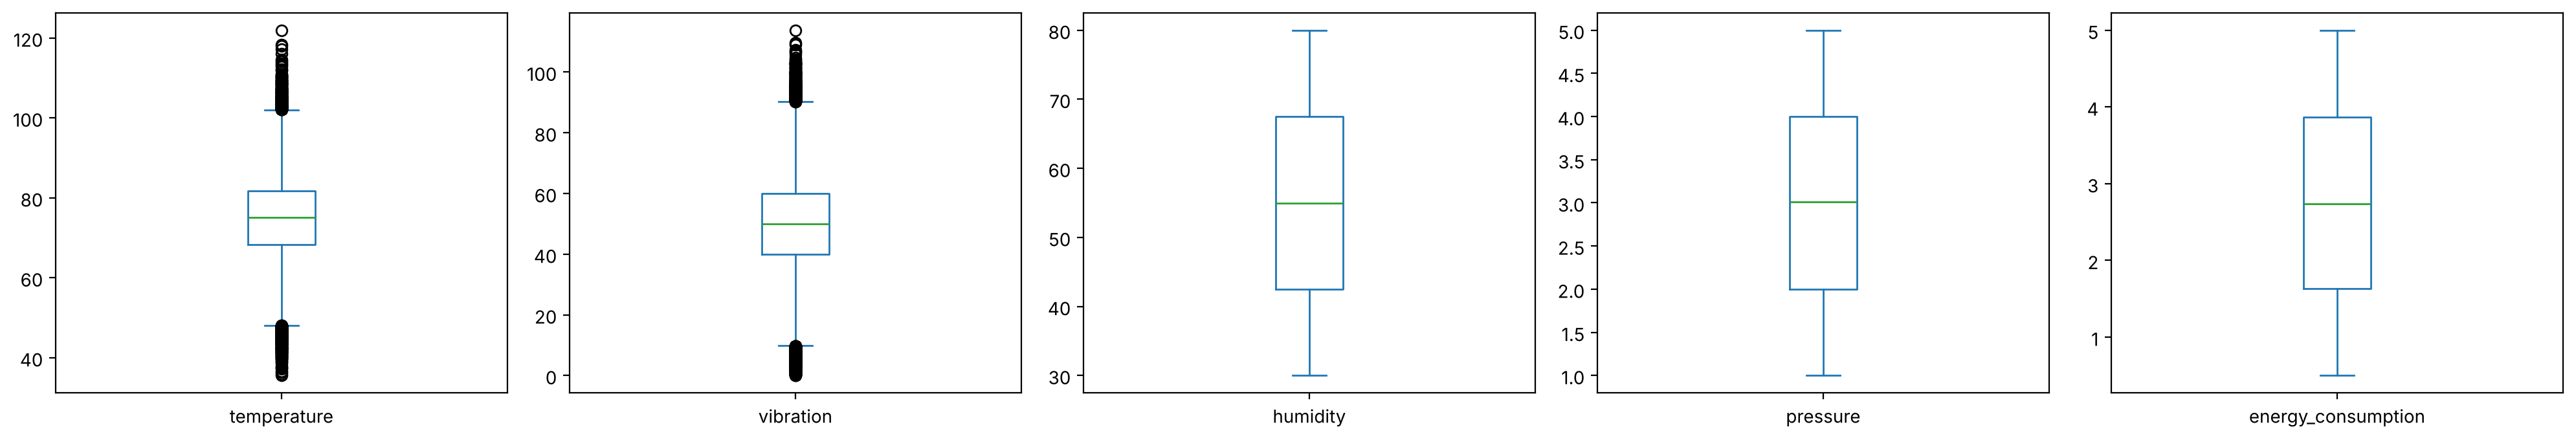

In [19]:
df_clean[SENSORS].plot(kind="box", subplots=True, layout=(1, 5), figsize=(20, 3.5))
plt.tight_layout()
plt.show()

The boxplots only show dots (outliers) for temperature and vibration. To confirm this with numbers, we use two common outlier rules:
- **1.5 x IQR rule:** below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR. This is the same rule the boxplot uses.
- **3σ rule:** below mean - 3 x standard deviation or above mean + 3 x standard deviation.

**Why this table:** for all 5 sensors and both rules, it counts the outliers and shows how often they need maintenance. This tells us whether they are useful or just noise. For temperature we use only the real readings, because the 14,000 filled-in medians are not real measurements.

In [20]:
rows = []
for col in SENSORS:
    values = df_clean[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    mean, std = values.mean(), values.std()
    limits = {"1.5 x IQR": (q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)),
              "3σ": (mean - 3 * std, mean + 3 * std)}
    for rule, (low_limit, high_limit) in limits.items():
        for side, outliers in [("low", values < low_limit), ("high", values > high_limit)]:
            rows.append({"sensor": col, "rule": rule, "side": side,
                         "limit": low_limit if side == "low" else high_limit,
                         "outliers": outliers.sum(),
                         "% needing maintenance": df_clean.loc[outliers[outliers].index, TARGET].mean() * 100})
pd.DataFrame(rows).round(1)

,sensor,rule,side,limit,outliers,% needing maintenance
0,temperature,1.5 x IQR,low,48.0,351,15.1
1,temperature,1.5 x IQR,high,102.0,298,100.0
2,temperature,3σ,low,44.9,135,19.3
3,temperature,3σ,high,105.1,114,100.0
4,vibration,1.5 x IQR,low,9.8,364,17.9
5,vibration,1.5 x IQR,high,90.3,350,100.0
6,vibration,3σ,low,5.1,124,16.1
7,vibration,3σ,high,94.9,145,100.0
8,humidity,1.5 x IQR,low,5.1,0,NaN
9,humidity,1.5 x IQR,high,105.0,0,NaN


**Findings**
- **humidity, pressure and energy_consumption have 0 outliers under both rules.** Their values stay inside fixed limits (for example, humidity is always between 30 and 80 %). Their maintenance rate shows as NaN because there are no outlier rows to measure.
- For **temperature and vibration**, **every high outlier needs maintenance (100 %) under both rules**. They are the most important readings, not mistakes.
- Their **low** outliers have a normal maintenance rate (about 15 % to 19 %, close to the 19.7 % average), so they are just the ends of a normal spread.

**Decision:** keep all outliers. Removing them would remove the readings that matter most.

## 6. Derived columns vs target
**Hypothesis:** the derived columns are calculated from other data, and the target might be calculated from them too. If so, using them in a model would be **cheating (data leakage)**: the model would look perfect, but would not work in real life.

**Why this table:** for each derived column, it shows the maintenance rate for each of its values.

In [21]:
for col in ["anomaly_flag", "machine_status", "failure_type"]:
    print((df_clean.groupby(col)[TARGET].mean() * 100).round(1), "\n")

anomaly_flag
0     11.8
1    100.0
Name: maintenance_required, dtype: float64 

machine_status
0     10.9
1     10.7
2    100.0
Name: maintenance_required, dtype: float64 

failure_type
Electrical Fault    100.0
Normal               12.6
Overheating         100.0
Pressure Drop       100.0
Vibration Issue     100.0
Name: maintenance_required, dtype: float64 



**Why this table:** remaining life is a number, so we group it into ranges first.

In [22]:
life_groups = pd.cut(df_clean["predicted_remaining_life"], bins=[0, 10, 20, 30, 50, 100, 500], right=False)
(df_clean.groupby(life_groups, observed=True)[TARGET].mean() * 100).round(1)

predicted_remaining_life
[0, 10)       100.0
[10, 20)      100.0
[20, 30)       53.7
[30, 50)       54.9
[50, 100)      10.0
[100, 500)     10.0
Name: maintenance_required, dtype: float64

**Findings**
- When `anomaly_flag` = 1, maintenance is needed **100 %** of the time.
- When `machine_status` = 2 (failed), maintenance is needed **100 %** of the time. Every failure type (apart from the wrongly labelled "Normal" rows) is also 100 %.
- When remaining life is **below 20 hours**, maintenance is needed **100 %** of the time. From 20 hours up, it drops.

**Hypothesis:** these three conditions together explain every maintenance case.

In [23]:
rule = (df_clean["anomaly_flag"] == 1) | (df_clean["machine_status"] == 2) | (df_clean["predicted_remaining_life"] < 20)
print("Rows where the rule matches maintenance_required:", round((rule == (df_clean[TARGET] == 1)).mean() * 100, 2), "%")

Rows where the rule matches maintenance_required: 100.0 %


**Findings:** the rule matches **100 %** of rows. So:

> **maintenance_required = anomaly_flag OR machine failed OR remaining life < 20 hours**

**Question:** how many maintenance cases come from each condition?

anomaly                        8916
machine failed (no anomaly)    9133
remaining life < 20 only       1648
dtype: int64 

anomaly                        45.3
machine failed (no anomaly)    46.4
remaining life < 20 only        8.4
dtype: float64


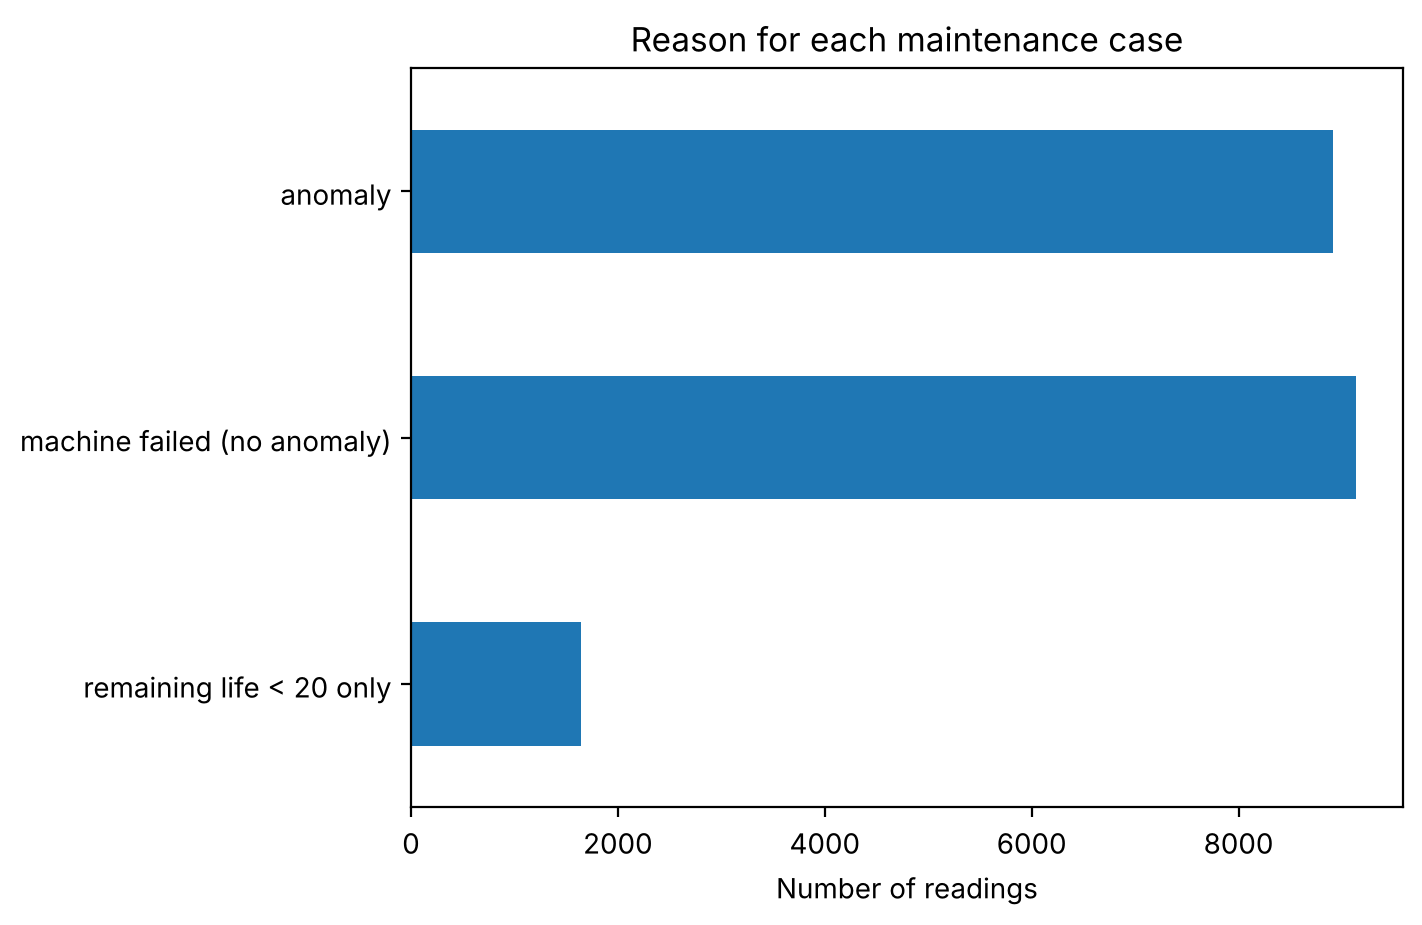

In [24]:
anomaly = df_clean["anomaly_flag"] == 1
failed = (df_clean["machine_status"] == 2) & ~anomaly
low_life = rule & ~anomaly & ~failed
reasons = pd.Series({"anomaly": anomaly.sum(), "machine failed (no anomaly)": failed.sum(),
                     "remaining life < 20 only": low_life.sum()})
print(reasons, "\n")
print((reasons / reasons.sum() * 100).round(1))

reasons.plot(kind="barh", title="Reason for each maintenance case")
plt.xlabel("Number of readings")
plt.gca().invert_yaxis()
plt.show()

**Findings:** 45 % of maintenance cases come from an anomaly, 46 % from failed machines and 8 % from low remaining life only.

**Question:** do failed machines have different sensor readings? If they do, the sensors could still help predict failures.

**Why this table:** it compares the average sensor readings for each machine status.

In [25]:
df_clean.groupby("machine_status")[SENSORS].mean().round(2)

,temperature,vibration,humidity,pressure,energy_consumption
machine_status,,,,,
0,75.13,49.77,54.88,3.0,2.76
1,75.01,50.05,55.01,3.0,2.75
2,75.09,49.97,54.98,3.0,2.74


**Findings:** the averages are almost the same for idle, running and failed machines. **Failures do not show up in the sensors.**

**Decision: which columns can be used to train models?**

| Column | Use for training? | Reason |
|---|---|---|
| temperature, vibration, humidity, pressure, energy_consumption | ✅ Yes | Real sensor readings, available before a failure |
| anomaly_flag, downtime_risk | ❌ No | Part of the target's rule (leakage). `downtime_risk` is basically a copy of `anomaly_flag` |
| predicted_remaining_life | ❌ No | Part of the target's rule (leakage) |
| machine_status, failure_type | ❌ No | Only known **after** a machine fails, which is too late for an alert |

The derived columns are still useful in the EDA: they explain how the target is made.

## 7. Sensors vs target
**Question:** which sensors are linked to maintenance? First we compare each sensor's values for readings that need maintenance (1) and readings that do not (0).

**Why these boxplots:** each box shows the middle 50 % of the values, and the line inside it is the median. If a sensor matters, its box for 1 should sit at a different height from its box for 0. Each sensor has its own chart and its own scale, so sensors with bigger numbers do not look more important.

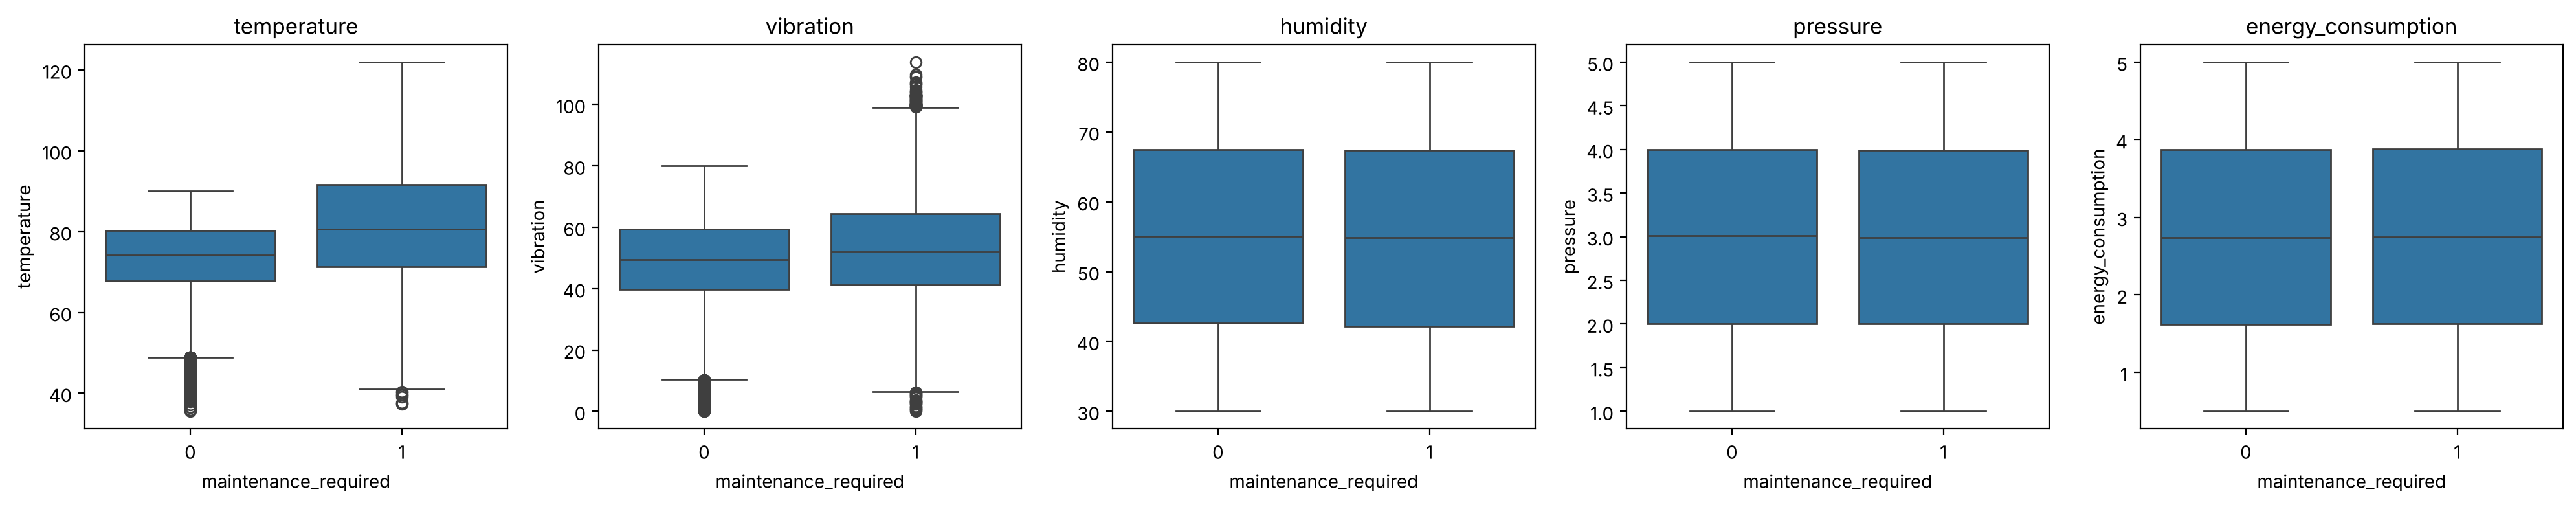

In [26]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, SENSORS):
    sns.boxplot(data=df_clean, x=TARGET, y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Why this table:** it gives the exact medians behind the boxplots.

In [27]:
df_clean.groupby(TARGET)[SENSORS].median().round(2)

,temperature,vibration,humidity,pressure,energy_consumption
maintenance_required,,,,,
0,74.23,49.53,55.01,3.01,2.74
1,80.66,51.90,54.85,2.99,2.75


**Findings**
- **temperature:** the box for maintenance (1) sits clearly higher, with a median of 80.7 °C vs 74.2 °C. Readings that do **not** need maintenance never go above **90 °C** (the top whisker for 0 stops there).
- **vibration:** the box for 1 is slightly higher (median 51.9 vs 49.5 mm/s), and readings that do not need maintenance never go above **80 mm/s**.
- **humidity, pressure, energy_consumption:** the boxes for 0 and 1 are almost identical, so these sensors do not seem to be linked to maintenance.
- The boxes for 1 still overlap a lot with the boxes for 0, so many maintenance cases have normal-looking sensor values.

**Question:** how strong is each link? We use correlation to put a number on it.

**Why this table (heatmap):** correlation shows how strongly two columns move together, from -1 to +1. 0 means no straight-line link. We use `temperature_filled` (the cleaned column), because the raw `temperature` is always empty when `temperature_missing` = 1, and that pair would show up as a blank cell.

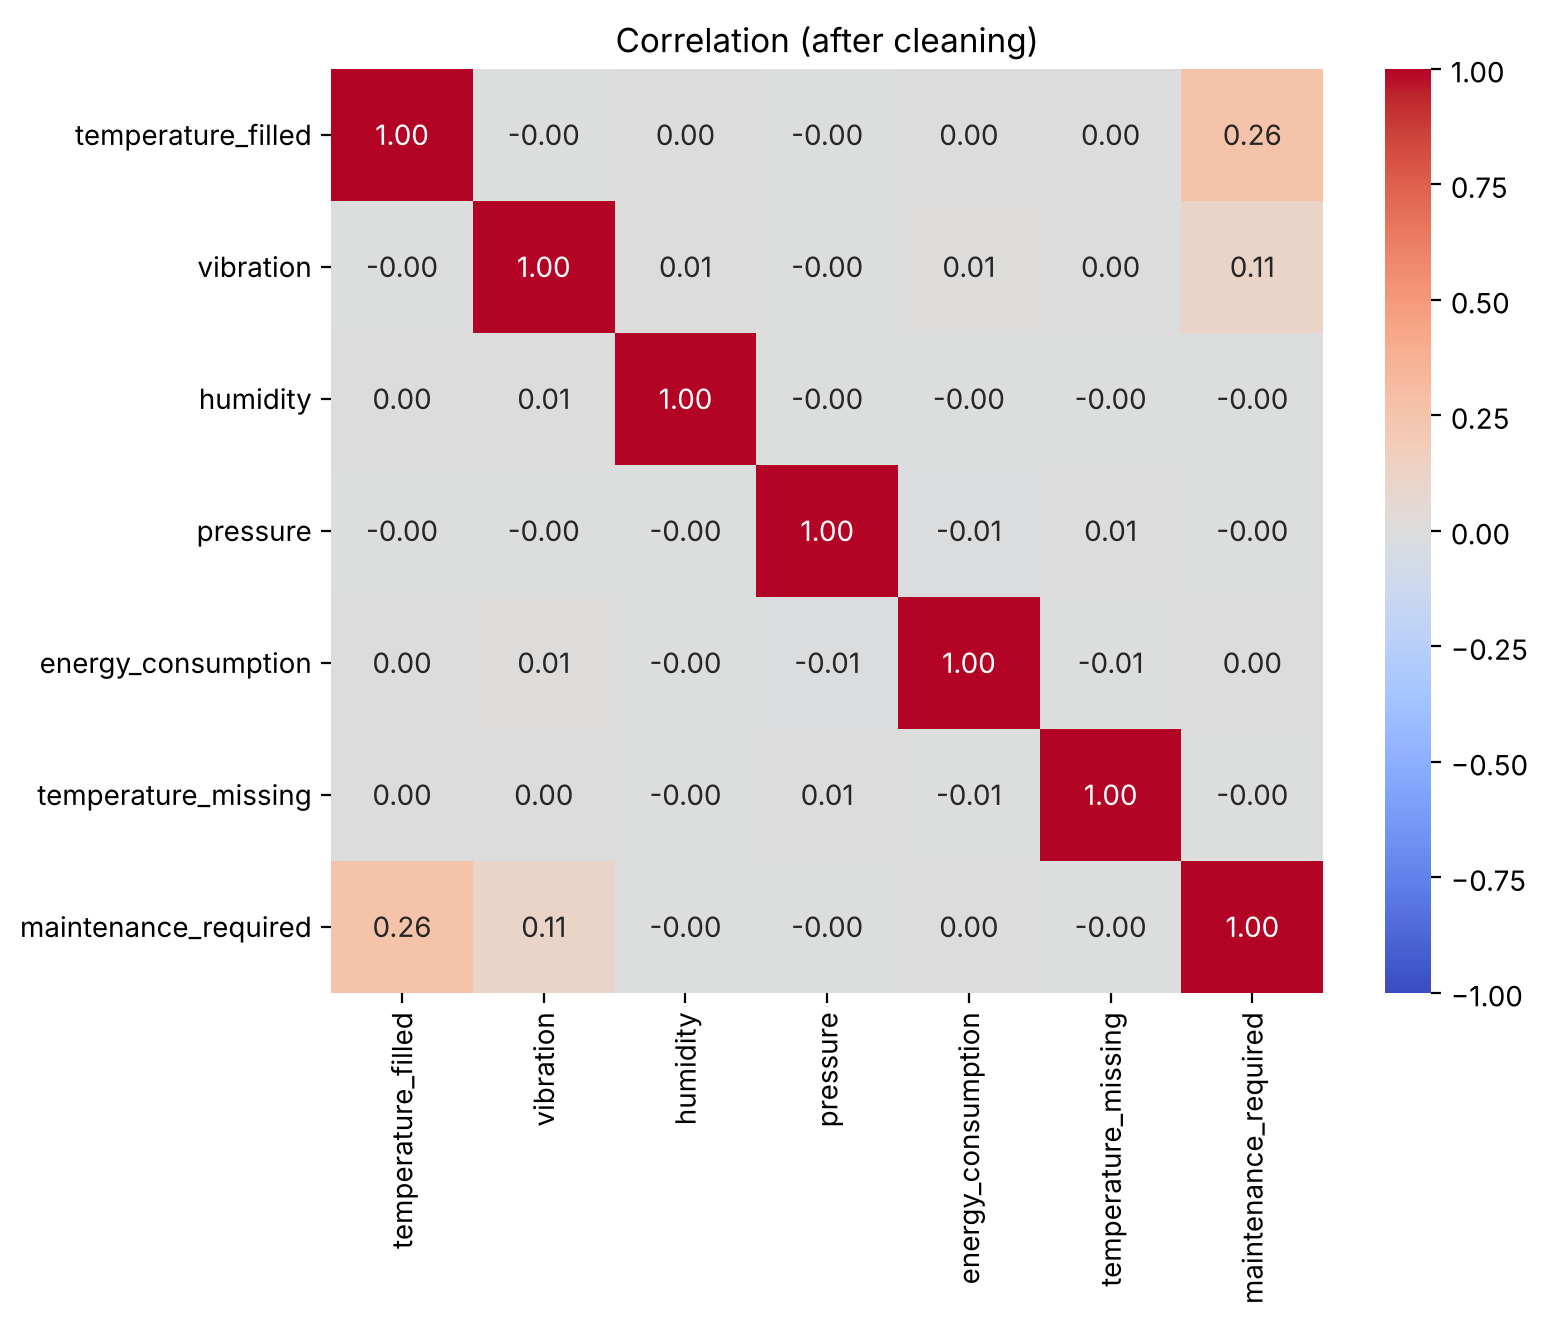

Temperature vs target, real readings only: 0.283
Temperature vs target, after filling:      0.262
Vibration vs target before cleaning: 0.051
Vibration vs target after cleaning:  0.113


In [28]:
cols = ["temperature_filled", "vibration", "humidity", "pressure", "energy_consumption", "temperature_missing", TARGET]
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation (after cleaning)")
plt.show()

print("Temperature vs target, real readings only:", round(df_clean["temperature"].corr(df_clean[TARGET]), 3))
print("Temperature vs target, after filling:     ", round(df_clean["temperature_filled"].corr(df_clean[TARGET]), 3))
print("Vibration vs target before cleaning:", round(df["vibration"].corr(df[TARGET]), 3))
print("Vibration vs target after cleaning: ", round(df_clean["vibration"].corr(df_clean[TARGET]), 3))

**Findings**
- Temperature (0.26) and vibration (0.11) are linked to maintenance, while humidity, pressure, energy and `temperature_missing` are not (about 0).
- Filling missing temperatures with the median **slightly weakens** temperature's link (0.28 with real readings only, 0.26 after filling). This is because 14,000 rows get the same middle value. It is expected, and it is why we also keep the `temperature_missing` column.
- Cleaning helped vibration: before taking the absolute value, its link was only 0.05.

**Question:** the sensors use very different scales. Temperature is around 75, while pressure only goes from 1 to 5. Does this give the bigger-numbered sensors extra weight? To check, we **normalise** every sensor (z-score: subtract the mean, divide by the standard deviation, so every sensor has mean 0 and standard deviation 1), then compare the correlations before and after.

In [29]:
normalised = (df_clean[SENSORS] - df_clean[SENSORS].mean()) / df_clean[SENSORS].std()

pd.DataFrame({
    "correlation (original)": df_clean[SENSORS].corrwith(df_clean[TARGET]),
    "correlation (normalised)": normalised.corrwith(df_clean[TARGET]),
}).round(3)

,correlation (original),correlation (normalised)
temperature,0.283,0.283
vibration,0.113,0.113
humidity,-0.004,-0.004
pressure,-0.002,-0.002
energy_consumption,0.001,0.001


**Findings:** the correlations are **exactly the same** before and after normalising. Correlation does not depend on scale, and the boxplots and rate charts in this section look at one sensor at a time, each on its own axis. So **no sensor gets extra weight in the EDA**, and we keep the original units (such as 90 °C), which are easier to read.

*For Task 2:* scale does matter for some models (such as logistic regression). There, the sensors should be normalised, with the mean and standard deviation calculated from the **training data only**. Tree-based models do not need it.

**Question:** correlation only measures straight-line links. Does the maintenance rate rise gradually, or does it jump at a certain value? We plot the maintenance rate across each sensor's range.

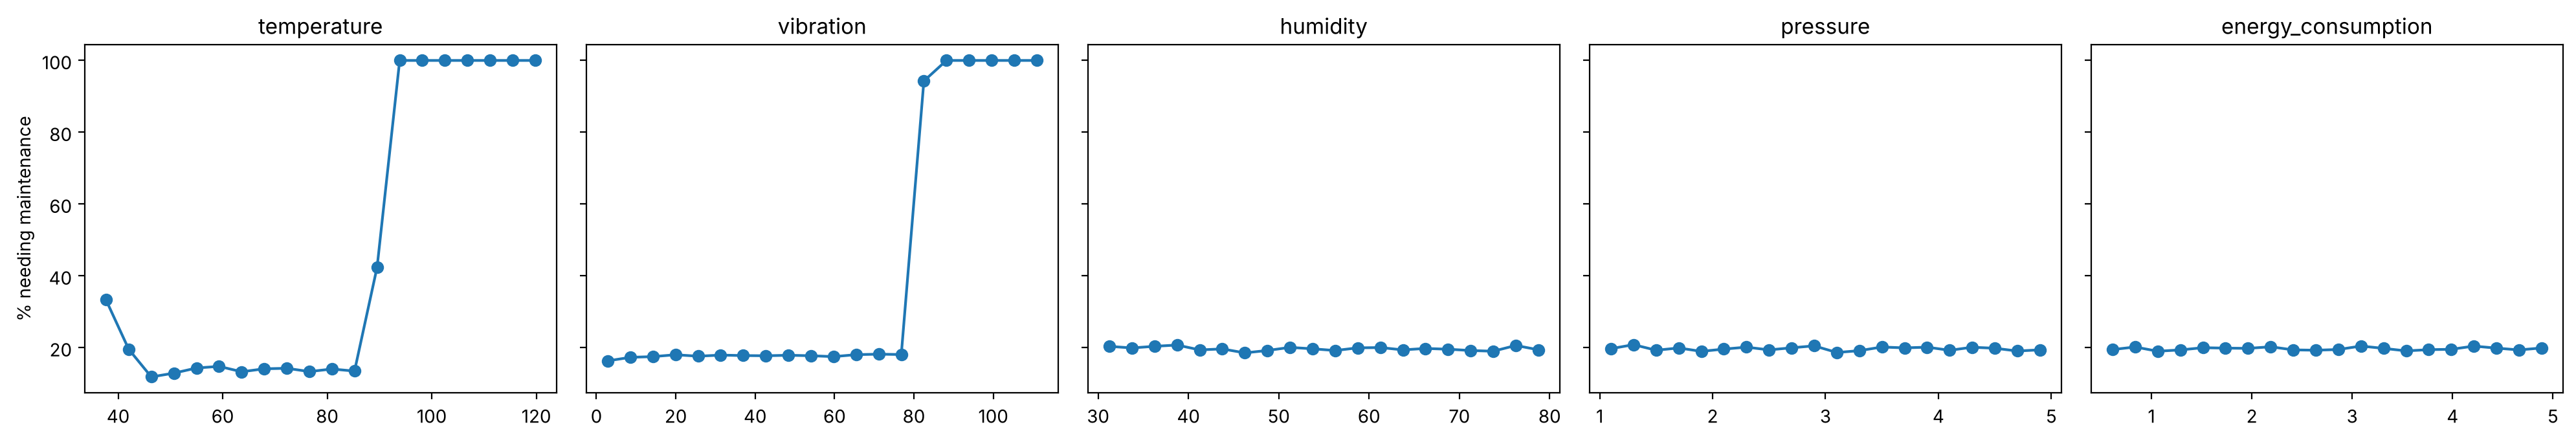

In [30]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5), sharey=True)
for ax, col in zip(axes, SENSORS):
    data = df_clean[[col, TARGET]].dropna()
    rate = data.groupby(pd.cut(data[col], 20), observed=True)[TARGET].mean() * 100
    ax.plot([b.mid for b in rate.index], rate.values, marker="o")
    ax.set_title(col)
axes[0].set_ylabel("% needing maintenance")
plt.tight_layout()
plt.show()

**Findings:** the rate stays flat, then jumps to 100 % at around **90 °C** for temperature and **80 mm/s** for vibration. Humidity, pressure and energy stay flat the whole way.

**Question:** do these two cut-offs separate the classes? We plot temperature against vibration and draw lines at 90 and 80.

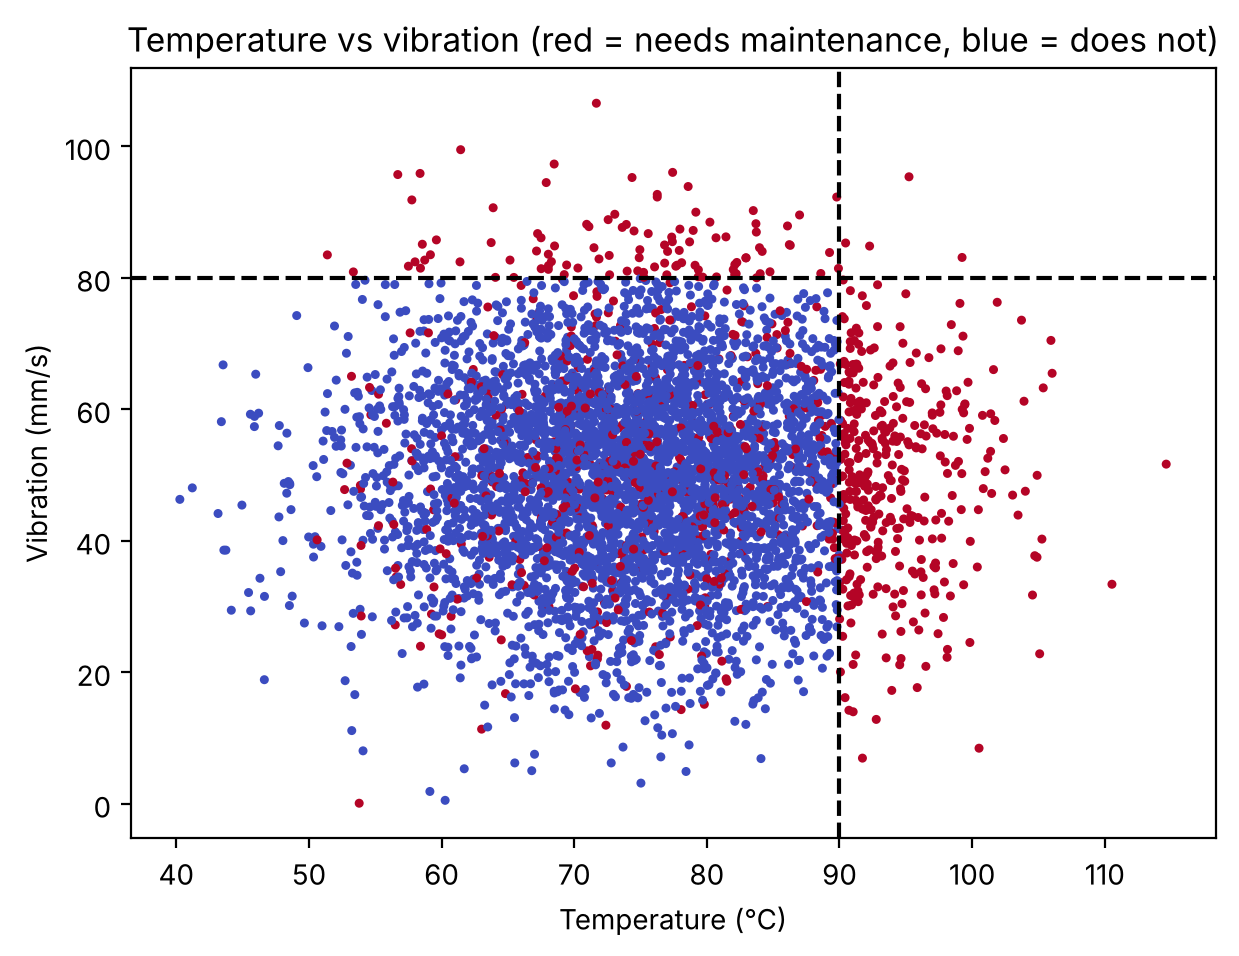

Maintenance rate above either line: 100.0 %
Maintenance rate below both lines:  11.9 %


In [31]:
sample = df_clean.dropna(subset=["temperature"]).sample(5000, random_state=42)
plt.figure(figsize=(7, 5))
plt.scatter(sample["temperature"], sample["vibration"], c=sample[TARGET], cmap="coolwarm", s=5)
plt.axvline(90, color="black", linestyle="--")
plt.axhline(80, color="black", linestyle="--")
plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration (mm/s)")
plt.title("Temperature vs vibration (red = needs maintenance, blue = does not)")
plt.show()

above = (df_clean["temperature"] > 90) | (df_clean["vibration"] > 80)
below_both = (df_clean["temperature"] <= 90) & (df_clean["vibration"] <= 80)
print("Maintenance rate above either line:", round(df_clean.loc[above, TARGET].mean() * 100, 1), "%")
print("Maintenance rate below both lines: ", round(df_clean.loc[below_both, TARGET].mean() * 100, 1), "%")

**Findings**
- Above 90 °C **or** 80 mm/s, **100 %** of readings need maintenance. These are the anomalies from Section 6.
- Below both lines, about 12 % still need maintenance, and red and blue points are mixed together. These cases come from failed machines and low remaining life, which the sensors cannot see.
- So the sensors can only explain the anomaly cases: **at most about 45 % of all maintenance cases** (Section 6). It is slightly less in practice, because some temperatures are missing.
- *For Task 2:* the link is a sudden jump, not a straight line. Models that use cut-off points (decision trees and tree ensembles such as Random Forest) should handle this well. A linear model such as Logistic Regression fits a smooth line, so it would need extra columns like "temperature > 90". Gaussian Naive Bayes is also a weaker fit, because three of the sensors are flat rather than bell-shaped (Section 3).

## 8. Machine and time
**Question:** do some machines, hours, weekdays or weeks need maintenance more often? If so, they could be useful features.

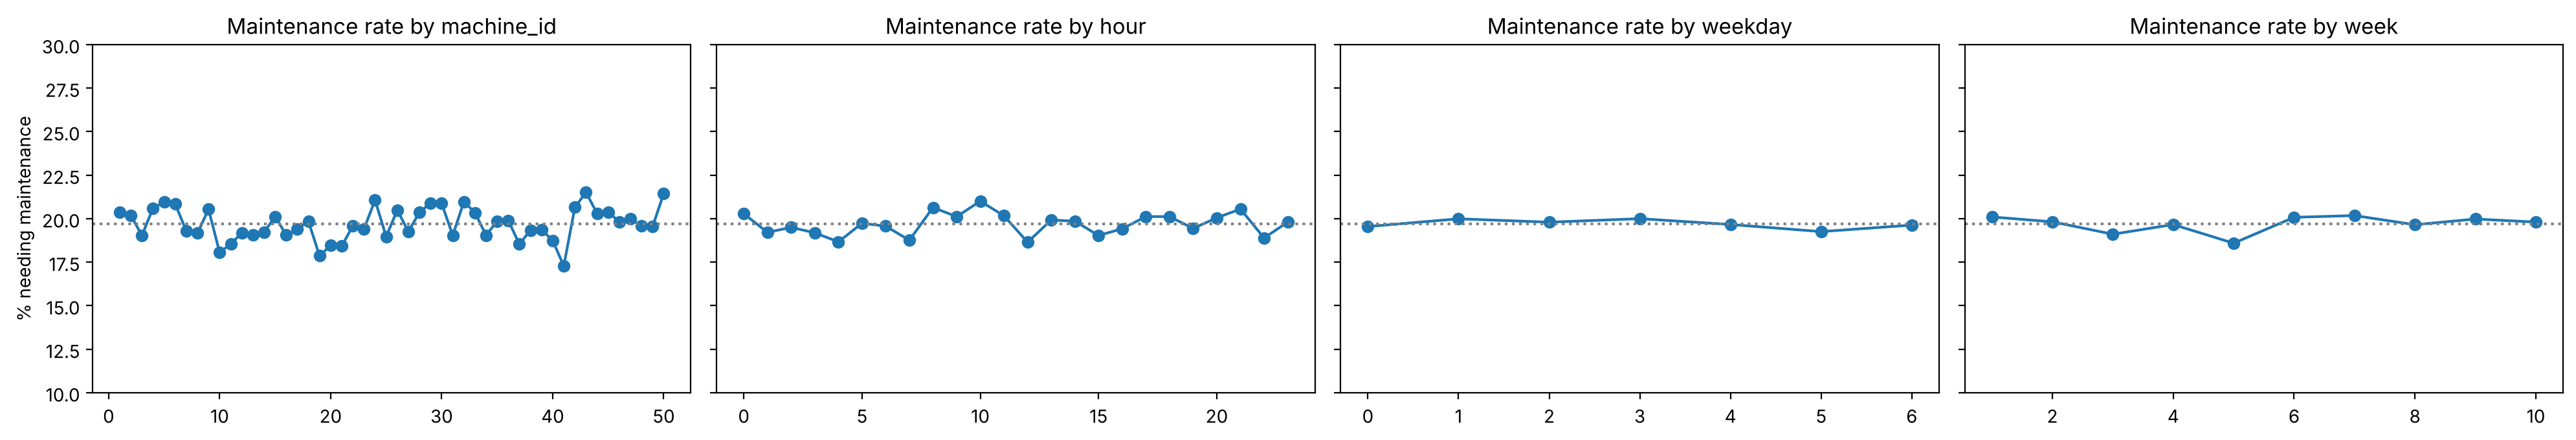

machine_id: 17.3 % to 21.5 %
hour: 18.6 % to 21.0 %
weekday: 19.3 % to 20.0 %
week: 18.6 % to 20.2 %


In [32]:
df_clean["hour"] = df_clean["timestamp"].dt.hour
df_clean["weekday"] = df_clean["timestamp"].dt.dayofweek          # 0 = Monday
df_clean["week"] = (df_clean["timestamp"] - df_clean["timestamp"].min()).dt.days // 7 + 1

fig, axes = plt.subplots(1, 4, figsize=(20, 3.5), sharey=True)
for ax, col in zip(axes, ["machine_id", "hour", "weekday", "week"]):
    rate = df_clean.groupby(col)[TARGET].mean() * 100
    ax.plot(rate.index, rate.values, marker="o")
    ax.axhline(df_clean[TARGET].mean() * 100, color="grey", linestyle=":")
    ax.set_title(f"Maintenance rate by {col}")
    ax.set_ylim(10, 30)
axes[0].set_ylabel("% needing maintenance")
plt.tight_layout()
plt.show()

for col in ["machine_id", "hour", "weekday", "week"]:
    rate = df_clean.groupby(col)[TARGET].mean() * 100
    print(f"{col}: {rate.min():.1f} % to {rate.max():.1f} %")

**Findings:** every machine, hour, weekday and week stays close to the overall 19.7 % (the dotted line): machines range from 17.3 % to 21.5 %, hours from 18.6 % to 21.0 %, weekdays from 19.3 % to 20.0 % and weeks from 18.6 % to 20.2 %. The small differences go up and down with no pattern. **No machine or time needs maintenance more often**, so these will not be useful features. `machine_id` is still needed to tell the team *which* machine to check.

**Question:** does a machine's previous reading help predict its next one? If machines wore down slowly, readings from the same machine should be similar over time.

**Why this table:** for each machine, it measures how similar each reading is to that machine's previous reading (a correlation from -1 to +1).

In [33]:
by_machine = df_clean.sort_values(["machine_id", "timestamp"]).groupby("machine_id")
pd.Series({col: by_machine[col].apply(lambda s: s.autocorr()).mean()
           for col in SENSORS + ["predicted_remaining_life", TARGET]},
          name="link to the machine's previous reading").round(3).to_frame()

,link to the machine's previous reading
temperature,-0.003
vibration,0.002
humidity,-0.000
pressure,0.003
energy_consumption,0.003
predicted_remaining_life,0.002
maintenance_required,0.006


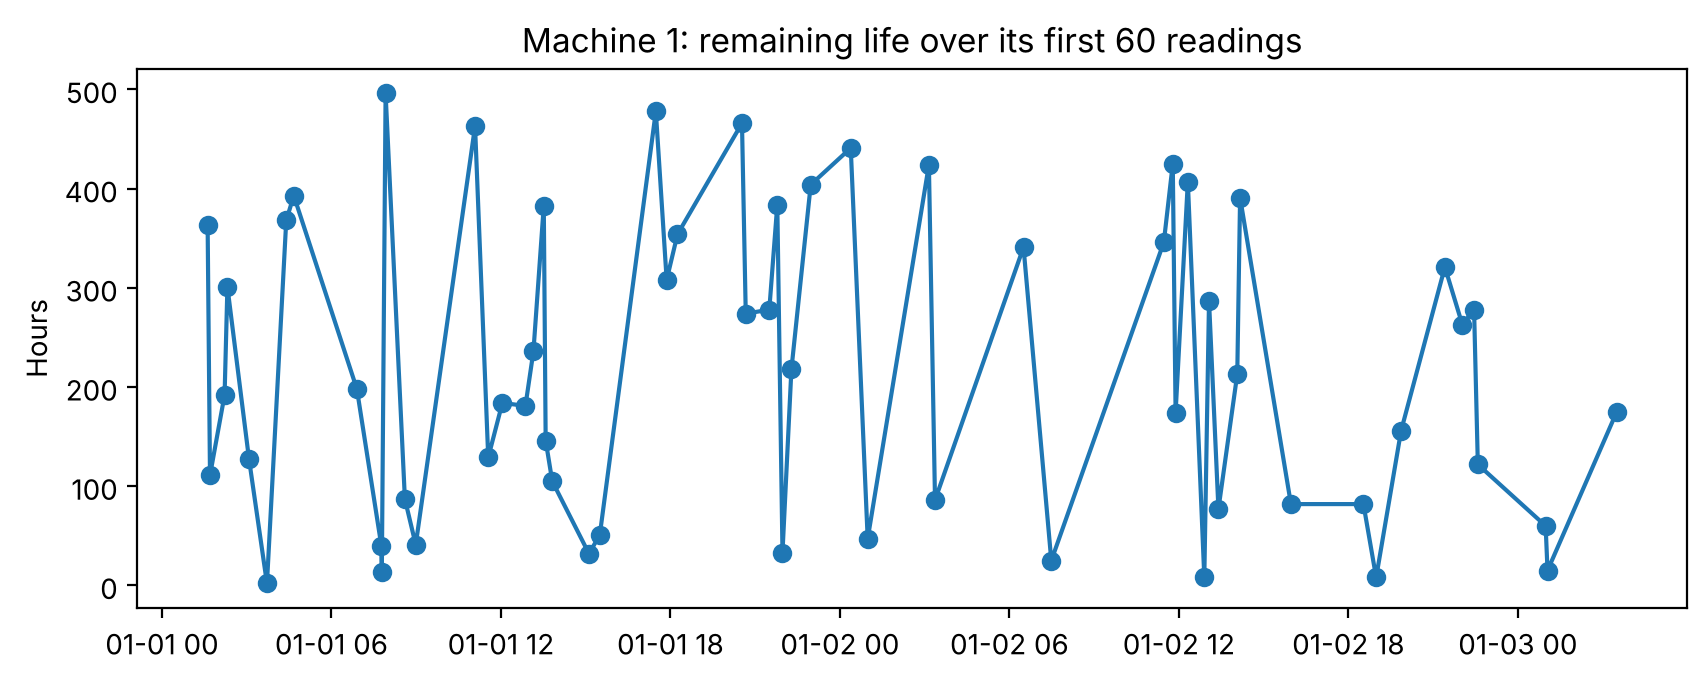

In [34]:
machine_1 = df_clean[df_clean["machine_id"] == 1].head(60)
plt.figure(figsize=(10, 3.5))
plt.plot(machine_1["timestamp"], machine_1["predicted_remaining_life"], marker="o")
plt.title("Machine 1: remaining life over its first 60 readings")
plt.ylabel("Hours")
plt.show()

**Findings:** every value is about 0, so a reading is **not linked** to the same machine's previous reading. Machine 1's remaining life jumps up and down instead of counting down. A machine's history does not help, so alerts can only be based on **each current reading**.

**Question:** Task 2 will probably train on older data and test on newer data. Do both parts have a similar maintenance rate?

In [35]:
split = int(len(df_clean) * 0.8)
print("Maintenance rate, first 80 % of time:", round(df_clean[TARGET].iloc[:split].mean() * 100, 1), "%")
print("Maintenance rate, last 20 % of time: ", round(df_clean[TARGET].iloc[split:].mean() * 100, 1), "%")

Maintenance rate, first 80 % of time: 19.6 %
Maintenance rate, last 20 % of time:  19.9 %


**Findings:** yes, both parts are similar (19.6 % vs 19.9 %), so splitting by time is fine for Task 2.

## 9. Decisions

| Decision | Reason | Section |
|---|---|---|
| Use the absolute value of vibration | Negative values are real readings with a wrong minus sign | 5.1 |
| Fill missing temperature with the median and add `temperature_missing` | Missing at random; mean ≈ median; no other sensor can help guess it; missing rows are riskier | 5.2 |
| Keep outliers | High temperatures all need maintenance | 5.3 |
| Do not train on the derived columns | They make up the target's rule (leakage), or are only known after a failure | 6 |
| Do not use machine_id or time as features | No difference between machines or times | 8 |
| Do not normalise in the EDA; normalise in Task 2 for models that need it | Correlations are identical after normalising, and each sensor is analysed on its own scale | 7 |
| Focus on recall in Task 2 | Missing a breakdown is worse than a false alarm | 2 |

## 10. Summary
1. **The data is clean overall:** no duplicates, correct types, and one reading per minute from 50 machines over about 10 weeks. The data looks simulated.
2. **Two problems fixed:** missing temperature (14 %) is filled with the median plus a "missing" column, and negative vibration (6.7 %) is turned positive.
3. **The target follows a simple rule:** anomaly OR machine failed OR remaining life < 20 hours. These columns are not used for training, because they give away the answer.
4. **Only temperature (> 90 °C) and vibration (> 80 mm/s) matter.** Humidity, pressure, energy, machine and time do not.
5. **The sensors can explain at most about 45 % of maintenance cases.** Failed machines and low remaining life leave no sign in the sensors. To catch more breakdowns early, the company would need more or better sensors.

**For Task 2 (pipeline):** load the data with SQLite, take the absolute value of vibration, add `temperature_missing`, fill temperature with the training-data median, normalise the sensors for models that need it (using the training data only), train on sensor columns only, split by time, and focus on recall.